# Quantum Oracle Sketching (QOS): a walkthrough

This notebook explains what QOS is, shows its core trick working on a toy problem, and then shows the limitations found when testing it on public financial data. It accompanies the report *Quantum Oracle Sketching on Bank-Held Data* and the repository [`qos-rbc-experiments`](https://github.com/THAKKAR82/qos-rbc-experiments) (tag `v1-qos-findings`).

**Two ways to present it**

| Audience | Time | What to show |
|---|---|---|
| Non-technical | ~15 min | Run all cells. Talk through the **For everyone** cells and the charts. Skip the **Technical note** cells. |
| Technical | ~30 min | Everything, including the **Technical note** cells and the code. |

**Everything here is a classical simulation on a laptop.** Nothing runs on a quantum computer. Sections 1–3 are toy demonstrations of the mechanism; Sections 4–6 use the measured results from the project.

Runs in the project's main environment (`numpy`, `matplotlib`, `scikit-learn`) in well under a minute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction import FeatureHasher
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer

rng = np.random.default_rng(42)

# One consistent, colour-blind-checked palette; at most three series per chart.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10.5, "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False,
})

## 1. The problem: getting classical data into a quantum computer

**For everyone.** Quantum algorithms are fast because they can look at *all* the data at once ("in superposition"). But bank data lives in ordinary files. Before a quantum computer can use it, someone has to build that all-at-once access, called an **oracle**.

The usual way is to store the whole dataset inside a special quantum memory (QRAM/QROM). That is expensive, and it can wipe out the speed-up the algorithm promised.

**QOS's idea:** don't store the data. Let it stream past, one random example at a time, and let each example nudge the quantum state by a *tiny* amount. After enough examples, the nudges add up to the oracle we wanted. Then the data is thrown away.

We'll build the simplest possible oracle: a list of 16 items, each tagged "yes" (1) or "no" (0). The oracle should flip the sign of every "yes" item:

$$O_f\,|x\rangle = (-1)^{f(x)}\,|x\rangle .$$

16 items need only 4 qubits, so we can simulate it exactly.

In [2]:
N = 16                                # 16 items -> 4 qubits
f = rng.integers(0, 2, size=N)        # hidden yes/no tag for each item
target_phase = np.pi * f              # the oracle we want: phase pi on "yes" items
print("hidden tags f(x):", f)
print("fraction of 'yes' items:", f.mean())

hidden tags f(x): [0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1]
fraction of 'yes' items: 0.625


## 2. The trick: many small nudges instead of one big flip

**For everyone.** Each streamed example says "item *x* is yes/no". We compare two ways of using it:

* **Big flip (store nothing, naive):** flip the sign of item *x* every time it shows up. Because examples repeat at random and we don't remember which we've seen, an item seen twice gets flipped back. The result is scrambled.
* **QOS small nudge:** rotate item *x* by a tiny angle every time it shows up. Repeats are harmless; they simply add more tiny angles, and on average everything lands in the right place.

The pictures below show each item as an arrow on a dial. The **orange** arrows are where they should end up; **blue** is where the stream has pushed them.

/tmp/ipykernel_230/1343173949.py:37: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


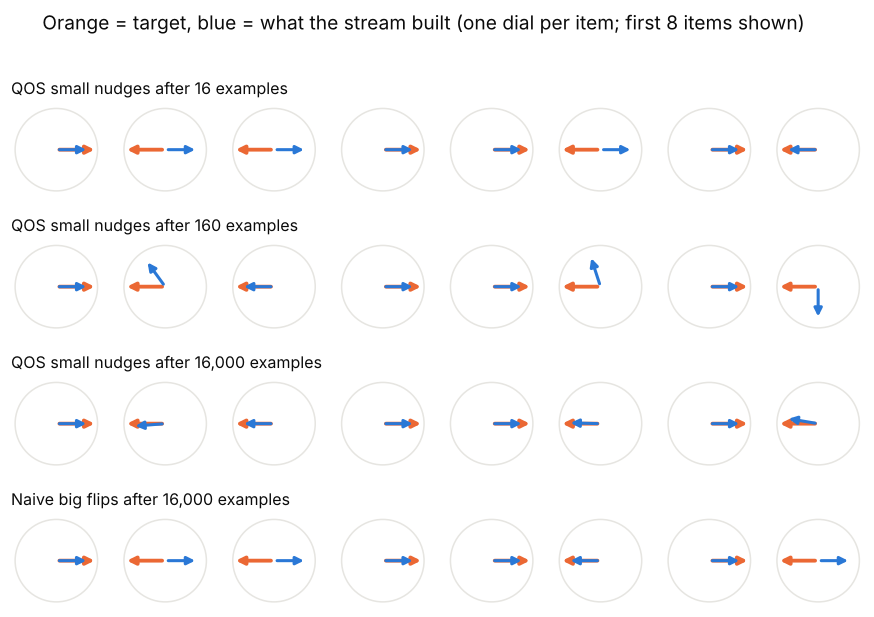

In [3]:
def stream_counts(M, N, rng):
    # How many times each item appears in a stream of M uniformly random examples.
    return np.bincount(rng.integers(0, N, size=M), minlength=N)

def qos_phase(counts, f, M, N):
    # Small nudge: each visit adds pi * N / M, so on average item x gets pi * f(x).
    return np.pi * f * counts * N / M

def big_flip_phase(counts, f):
    # Naive store-nothing approach: flip on every visit (repeats undo each other).
    return np.pi * f * (counts % 2)

def draw_dials(ax_row, phases, title):
    for x, ax in enumerate(ax_row[:SHOW]):
        ax.set_aspect("equal"); ax.axis("off")
        ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=GRID, lw=1))
        t = target_phase[x]
        ax.annotate("", xy=(np.cos(t), np.sin(t)), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=2.5))
        p = phases[x]
        ax.annotate("", xy=(0.8*np.cos(p), 0.8*np.sin(p)), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=2))
        ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
    ax_row[0].text(-1.1, 1.35, title, fontsize=10.5, color=INK, ha="left")

stream_rng = np.random.default_rng(7)
Ms = [16, 160, 16_000]
SHOW = 8                                   # draw the first 8 items so the dials are readable
fig, axes = plt.subplots(len(Ms) + 1, SHOW, figsize=(10, 6.2))
for r, M in enumerate(Ms):
    c = stream_counts(M, N, stream_rng)
    draw_dials(axes[r], qos_phase(c, f, M, N), f"QOS small nudges after {M:,} examples")
c = stream_counts(16_000, N, stream_rng)
draw_dials(axes[-1], big_flip_phase(c, f), "Naive big flips after 16,000 examples")
fig.suptitle("Orange = target, blue = what the stream built (one dial per item; first 8 items shown)",
             y=1.0, color=INK)
fig.tight_layout()
plt.show()

**What to notice.** With few examples the QOS arrows wobble; with many they settle on the targets. The naive big-flip row stays scrambled no matter how many examples arrive, because each "yes" item ends up flipped an even or odd number of times by chance.

**Technical note.** A quantum algorithm doesn't see one particular stream; each use of the oracle is built from fresh random samples, so what matters is the *average* operation (a quantum channel). For item $x$ with $c_x \sim \mathrm{Binomial}(M, 1/N)$ visits, the average phase factor is

$$\mathbb{E}\!\left[e^{i\theta c_x}\right] = \left(1 - \tfrac{1}{N} + \tfrac{1}{N}e^{i\theta}\right)^{M}, \qquad \theta = \pi f(x)\,N/M .$$

For a "yes" item this is $\approx e^{i\pi}\,e^{-\pi^2 N/(2M)}$: the right phase, slightly shrunk. The error is $\approx \pi^2 N/(2M)$, so reaching error $\varepsilon$ takes $M \propto N/\varepsilon$ samples, the $\Theta(N/\varepsilon)$ scaling of the paper. The big-flip average is $(1-2/N)^M \to 0$: the oracle is erased entirely. (The paper's real construction for matrices is more involved; this is its simplest case.)

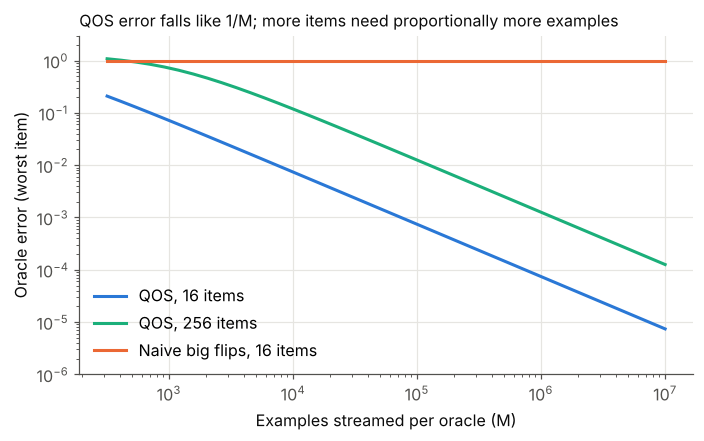

  16 items: about 7,896 examples per oracle for 1% error
 256 items: about 126,331 examples per oracle for 1% error


In [4]:
def avg_channel_error(M, N, f):
    # Worst-item error of the averaged (expected) oracle vs the exact one.
    theta = np.pi * f * N / M
    expected = (1 - 1/N + np.exp(1j * theta) / N) ** M
    return np.max(np.abs(expected - np.exp(1j * np.pi * f)))

def big_flip_avg_error(M, N, f):
    expected = np.where(f == 1, (1 - 2/N) ** M, 1.0)
    return np.max(np.abs(expected - np.exp(1j * np.pi * f)))

M_grid = np.unique(np.logspace(2.5, 7, 40).astype(int))
fig, ax = plt.subplots(figsize=(7.2, 4))
for n_items, col in [(16, BLUE), (256, AQUA)]:
    f_n = np.ones(n_items, dtype=int)            # worst case: every item is "yes"
    err = [avg_channel_error(M, n_items, f_n) for M in M_grid]
    ax.loglog(M_grid, err, color=col, label=f"QOS, {n_items} items")
f_n = np.ones(16, dtype=int)
ax.loglog(M_grid, [big_flip_avg_error(M, 16, f_n) for M in M_grid],
          color=ORANGE, label="Naive big flips, 16 items")
ax.set_xlabel("Examples streamed per oracle (M)")
ax.set_ylabel("Oracle error (worst item)")
ax.set_ylim(1e-6, 3)
ax.set_title("QOS error falls like 1/M; more items need proportionally more examples",
             loc="left", color=INK, fontsize=10.5)
ax.legend(loc="lower left")
plt.show()

for n_items in (16, 256):
    M_needed = np.pi**2 * n_items / (2 * 1e-2)
    print(f"{n_items:>4} items: about {M_needed:,.0f} examples per oracle for 1% error")

## 3. Using the oracle, and what each use costs

**For everyone.** Once built, the oracle can answer a question about *all* items in a single quantum step, for example "what fraction of items are 'yes'?". That's the appeal.

The catch: **each use of the oracle consumes its own fresh batch of examples**, and quantum answers are random, so the step has to be repeated many times to read the answer reliably. The sample meter adds up fast.

**Technical note.** The circuit is $H^{\otimes n} O_f H^{\otimes n}$ on $|0\rangle$. The probability of measuring $|0\dots0\rangle$ is $\big(\tfrac{1}{N}\sum_x (-1)^{f(x)}\big)^2 = (1-2\bar f)^2$, where $\bar f$ is the fraction of "yes" items. We simulate it with the sketched oracle and finite measurement shots.

In [5]:
def prob_all_zero(phases):
    # H^n O H^n |0>: amplitude of |0...0> is the mean of e^{i phase_x}.
    return np.abs(np.mean(np.exp(1j * phases))) ** 2

exact_p = prob_all_zero(target_phase)
M_per_query = 5_000
shots_list = [10, 100, 1_000, 10_000]
meter_rng = np.random.default_rng(3)

print(f"Exact P(all zeros) = {exact_p:.4f}   (true 'yes' fraction = {f.mean():.3f})\n")
print(f"{'shots':>7} {'estimated P':>12} {'examples consumed':>19}")
for shots in shots_list:
    hits = 0
    for _ in range(shots):        # every shot needs a freshly sketched oracle
        c = stream_counts(M_per_query, N, meter_rng)
        hits += meter_rng.random() < prob_all_zero(qos_phase(c, f, M_per_query, N))
    print(f"{shots:>7} {hits/shots:>12.4f} {shots*M_per_query:>19,}")

Exact P(all zeros) = 0.0625   (true 'yes' fraction = 0.625)

  shots  estimated P   examples consumed
     10       0.0000              50,000
    100       0.0700             500,000
   1000       0.0550           5,000,000


  10000       0.0574          50,000,000


**What to notice.** The estimate gets close to the exact value only after thousands of repetitions, and every repetition eats thousands of examples. For 16 items that's fine. The next sections show what happens to that bill on real bank data.

## 4. Why bank data breaks the guarantee: sparsity

**For everyone.** For realistic tasks such as classifying complaints, QOS sketches a whole *table* (documents × words), not a list. The paper's guarantee needs that table to be **sparse in both directions**: every document uses few words (rows), *and* every word appears in few documents (columns).

Language doesn't work that way. A handful of words ("account", "payment", "bank") appear in most documents. The busiest column grows with the dataset instead of staying small.

Below we generate realistic synthetic text (word frequencies following the same power law as real language) and measure the busiest column as the dataset grows. In the real CFPB complaint data the busiest word appeared in **58–71%** of complaints.

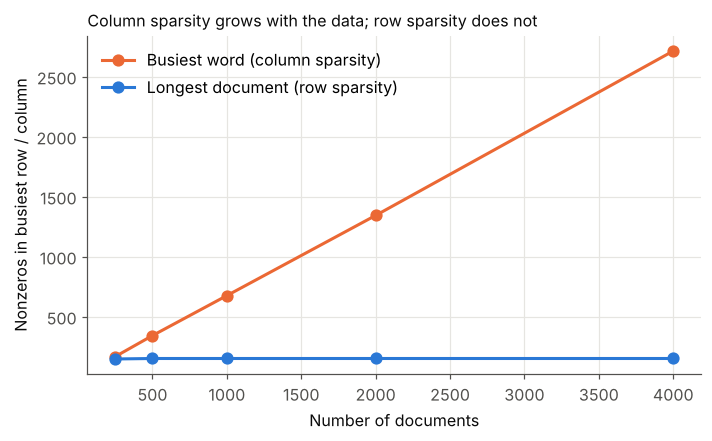

  250 documents: busiest word appears in 67% of them
  500 documents: busiest word appears in 68% of them
 1000 documents: busiest word appears in 68% of them
 2000 documents: busiest word appears in 67% of them
 4000 documents: busiest word appears in 68% of them


In [6]:
V = 20_000                                     # vocabulary size
ranks = np.arange(1, V + 1)
word_p = 1 / ranks                             # Zipf's law, as in natural language
word_p[:10] = 0                                # drop the 10 commonest words (like stop-word removal)
word_p /= word_p.sum()

def make_corpus(n_docs, rng, class_shift=None):
    docs, labels = [], []
    for _ in range(n_docs):
        y = rng.integers(0, 2)
        length = rng.integers(40, 160)
        p = word_p if class_shift is None else class_shift[y]
        words = rng.choice(V, size=length, p=p)
        docs.append(" ".join(f"w{w}" for w in words)); labels.append(y)
    return docs, np.array(labels)

sizes = [250, 500, 1_000, 2_000, 4_000]
corpus, _ = make_corpus(max(sizes), np.random.default_rng(11))
row_s, col_s = [], []
for n in sizes:
    X = CountVectorizer(token_pattern=r"\S+").fit_transform(corpus[:n])
    row_s.append(np.diff(X.indptr).max())
    col_s.append(np.diff(X.tocsc().indptr).max())

fig, ax = plt.subplots(figsize=(7.2, 4))
ax.plot(sizes, col_s, "o-", color=ORANGE, ms=7, label="Busiest word (column sparsity)")
ax.plot(sizes, row_s, "o-", color=BLUE, ms=7, label="Longest document (row sparsity)")
ax.set_xlabel("Number of documents"); ax.set_ylabel("Nonzeros in busiest row / column")
ax.set_title("Column sparsity grows with the data; row sparsity does not",
             loc="left", color=INK, fontsize=10.5)
ax.legend(loc="upper left")
plt.show()
for n, cs in zip(sizes, col_s):
    print(f"{n:>5} documents: busiest word appears in {cs/n:.0%} of them")

**Technical note.** The theorem's sample bound (Eq. F61 of Zhao et al.) grows like $s^{7}\kappa^{4}\gamma^{-4}$, where $s$ is the larger of row and column sparsity, $\kappa$ the condition number and $\gamma$ the smallest test margin. With $s \propto N$, the headline "polylog qubits, $\tilde O(N)$ samples" no longer applies. Tabular data is worse: a numeric column is nonzero in every row, so $s = N$ exactly (Bank Marketing: $s = 36{,}169$).

## 5. How big is the bill? (measured project results)

**For everyone.** The project measured, in simulation, how fast QOS's cost grows with sparsity. It grows more slowly than the paper's worst-case proof says (good news for QOS), but not nearly enough. The chart converts the corrected estimate into time: **if a machine processed one billion examples per second, how long would one quantum query take?**

These numbers come from `results/FINAL_SUMMARY.md` (tag `v1-qos-findings`) and are extrapolations, orders of magnitude only.

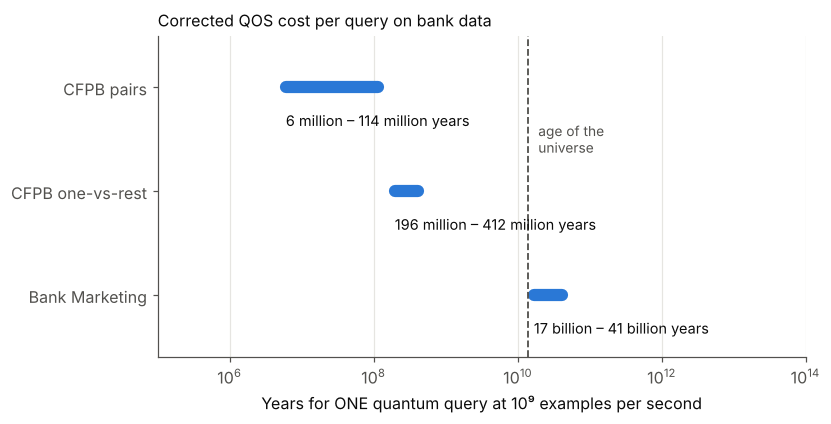

In [7]:
# Corrected (empirical) samples per block-encoding query, eps = 1e-2, from FINAL_SUMMARY.md
per_query = {
    "CFPB pairs":       (1.9e23, 3.6e24),
    "CFPB one-vs-rest": (6.2e24, 1.3e25),
    "Bank Marketing":   (5.3e26, 1.3e27),
}
rate = 1e9                      # samples per second (illustrative)
year = 3.156e7                  # seconds

def in_words(years):
    for scale, word in [(1e9, "billion"), (1e6, "million"), (1e3, "thousand")]:
        if years >= scale:
            return f"{years/scale:.0f} {word}"
    return f"{years:.0f}"

fig, ax = plt.subplots(figsize=(7.6, 3.8))
names = list(per_query)
for i, name in enumerate(names):
    lo, hi = (v / rate / year for v in per_query[name])
    ax.plot([lo, hi], [i, i], color=BLUE, lw=8, solid_capstyle="round")
    ax.text(lo, i + 0.32, f"{in_words(lo)} – {in_words(hi)} years", va="center",
            color=INK, fontsize=9.5)
ax.axvline(1.38e10, color=MUTED, lw=1.2, ls="--")
ax.text(1.38e10 * 1.4, 0.5, "age of the\nuniverse", color=MUTED, fontsize=9, va="center")
ax.set_xscale("log"); ax.set_xlim(1e5, 1e14)
ax.set_yticks(range(len(names)), names); ax.set_ylim(len(names) - 0.4, -0.5)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Years for ONE quantum query at 10⁹ examples per second")
ax.set_title("Corrected QOS cost per query on bank data", loc="left", color=INK, fontsize=10.5)
plt.show()

**What to notice.** A single query to the complaint data would take millions to hundreds of millions of years, and a classifier needs many queries. Bank Marketing's single-query cost exceeds the age of the universe.

**Technical note.** The project measured the sparsity exponent of the most expensive building block at $s^{3.1\text{–}3.3}$ instead of the proof's $s^{5}$, stable from $N=64$ to $N=128$. That removes 6–8 orders of magnitude from the bound: $10^{37}$–$10^{45}$ becomes $10^{30}$–$10^{37}$ passes over the data. The $\kappa$, $\gamma$ and $\delta$ factors keep their proof values (the end-to-end simulation was not run). Applied at $s$ in the thousands, this is a 2–3 decade extrapolation.

## 6. The classical comparison: kilobytes are enough

**For everyone.** QOS's whole selling point is saving memory. So how much memory does an ordinary computer need for this kind of task? We train a simple streaming classifier that reads each document once and keeps only a fixed-size table of numbers (the "hashing trick"), and vary the table's size.

On the real CFPB data, the project found classical learners reach **95% of full accuracy with 16–32 KiB** (a few thousand numbers) on held-out test data. Here's the same effect on synthetic data.

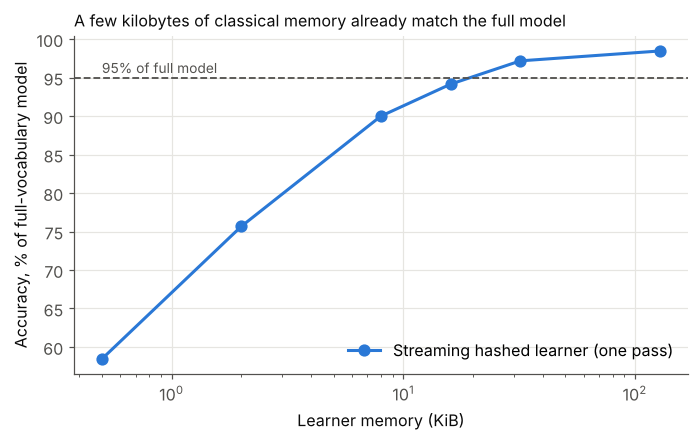

Full-vocabulary model: 19,874 features, test accuracy 0.975
   64 weights =  0.50 KiB ->  58.4% of full accuracy
  256 weights =  2.00 KiB ->  75.7% of full accuracy
 1024 weights =  8.00 KiB ->  90.0% of full accuracy
 2048 weights = 16.00 KiB ->  94.2% of full accuracy
 4096 weights = 32.00 KiB ->  97.2% of full accuracy
16384 weights = 128.00 KiB ->  98.5% of full accuracy


In [8]:
# Two-class synthetic corpus: each class over-uses its own set of topic words.
topic = {0: np.arange(150, 450), 1: np.arange(450, 750)}
class_p = {}
for y, words in topic.items():
    p = word_p.copy(); p[words] *= 2.5; class_p[y] = p / p.sum()
data_rng = np.random.default_rng(21)
train_docs, y_train = make_corpus(6_000, data_rng, class_p)
test_docs, y_test = make_corpus(2_000, data_rng, class_p)

def tokens(docs):
    return [d.split() for d in docs]

# Full-vocabulary reference model
vec = CountVectorizer(token_pattern=r"\S+", binary=True).fit(train_docs)
full = LogisticRegression(max_iter=2000).fit(vec.transform(train_docs), y_train)
full_acc = full.score(vec.transform(test_docs), y_test)

budgets = [64, 256, 1024, 2048, 4096, 16384]      # number of stored weights
accs = []
for k in budgets:
    hasher = FeatureHasher(n_features=k, input_type="string", alternate_sign=True)
    clf = SGDClassifier(loss="log_loss", alpha=1e-4, random_state=42)
    for i in range(0, len(train_docs), 500):        # single pass, in chunks
        batch = tokens(train_docs[i:i+500])
        clf.partial_fit(hasher.transform(batch), y_train[i:i+500], classes=[0, 1])
    accs.append(clf.score(hasher.transform(tokens(test_docs)), y_test))

kib = [k * 8 / 1024 for k in budgets]
fig, ax = plt.subplots(figsize=(7.2, 4))
ax.semilogx(kib, np.array(accs) / full_acc * 100, "o-", color=BLUE, ms=7,
            label="Streaming hashed learner (one pass)")
ax.axhline(95, color=MUTED, lw=1.2, ls="--")
ax.text(kib[0], 95.6, "95% of full model", color=MUTED, fontsize=9)
ax.set_xlabel("Learner memory (KiB)"); ax.set_ylabel("Accuracy, % of full-vocabulary model")
ax.set_title("A few kilobytes of classical memory already match the full model",
             loc="left", color=INK, fontsize=10.5)
ax.legend(loc="lower right")
plt.show()
print(f"Full-vocabulary model: {len(vec.vocabulary_):,} features, test accuracy {full_acc:.3f}")
for k, kb, a in zip(budgets, kib, accs):
    print(f"{k:>5} weights = {kb:>5.2f} KiB -> {a/full_acc:6.1%} of full accuracy")

**Technical note.** The real benchmark used feature hashing, sparse Johnson–Lindenstrauss projection and AWM-Sketch with tuned streaming SGD, 3 CFPB tasks, two featurizers, budgets 4–512 KiB, 3 seeds and bootstrap confidence intervals, with configurations frozen on validation and confirmed on the held-out test split. The memory that actually dominates is the **featurizer**: the frozen TF-IDF vocabulary is 8.2 MB, about 500× the learner, and any learner needs it, including a QOS sample stream.

## 7. Putting it together

**For everyone.** QOS promises to save memory. On the data tested there is almost no memory to save: a classical learner needs about 16–32 KiB. And QOS would pay for that tiny saving with an astronomical number of examples, so many that the data would have to be stored anyway, to be streamed past the machine about 4 × 10¹⁸ times per query.

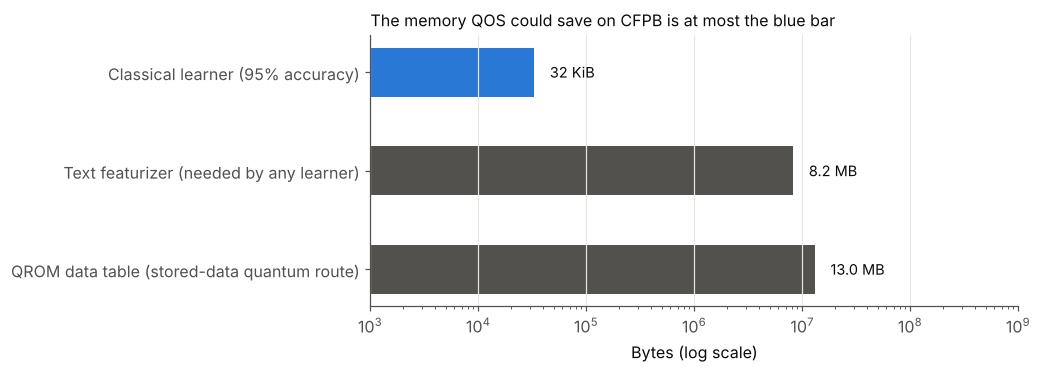

In [9]:
fig, ax = plt.subplots(figsize=(7.6, 3.2))
items = [
    ("Classical learner (95% accuracy)", 32 * 1024, BLUE),
    ("Text featurizer (needed by any learner)", 8.2e6, MUTED),
    ("QROM data table (stored-data quantum route)", 13e6, MUTED),
]
for i, (label, nbytes, col) in enumerate(items):
    ax.barh(i, nbytes, color=col, height=0.5)
    ax.text(nbytes * 1.4, i, f"{nbytes/1024:,.0f} KiB" if nbytes < 1e6 else f"{nbytes/1e6:.1f} MB",
            va="center", color=INK, fontsize=9.5)
ax.set_xscale("log"); ax.set_xlim(1e3, 1e9)
ax.set_yticks(range(len(items)), [i[0] for i in items]); ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Bytes (log scale)")
ax.set_title("The memory QOS could save on CFPB is at most the blue bar",
             loc="left", color=INK, fontsize=10.5)
plt.show()

### Takeaways

| | |
|---|---|
| **The idea is real** | Small rotations from a data stream do build a quantum oracle without storing the data (Section 2). |
| **The guarantee needs sparse data** | Rows *and* columns. Real text and tables aren't (Section 4). |
| **The cost is astronomical** | Even after correcting the proof with measured scaling: millions of years per query on CFPB (Section 5). |
| **Classical needs kilobytes** | 16–32 KiB matches the full model, so there's little memory to save (Section 6). |
| **Not a disproof** | The paper's theorem is a correct worst-case guarantee; it just doesn't reach the data tested. Bank data with bounded row *and* column sparsity, or genuinely unstorable streams, is untested; the report's *Candidate Bank Data* and *Next Steps* sections list what to check. |

### Glossary

* **Oracle:** quantum access to all data items at once.
* **Sketch:** a compact summary built from a stream without storing it.
* **Sparsity:** the most nonzeros in any row or column of the data table.
* **Margin:** how clearly a test example sits on one side of the decision boundary.
* **QROM:** the standard way to load a *stored* table into a quantum computer.
* **KiB:** 1,024 bytes; 16 KiB holds about 2,000 numbers.

**Sources.** Zhao et al., *Exponential quantum advantage in processing massive classical data*, arXiv:2604.07639v2. Project results: `results/FINAL_SUMMARY.md` in [`qos-rbc-experiments`](https://github.com/THAKKAR82/qos-rbc-experiments), tag `v1-qos-findings`.